<a href="https://colab.research.google.com/github/kimgj433/surveying2-team-3/blob/main/%EC%84%9C%EC%9A%B825%EA%B5%AC_%EC%95%BC%EA%B0%84%EA%B4%91%EB%9F%89.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 서울 25개 자치구 야간광량 분석
2019년 봄(3~5월)과 2020년 봄 비교 · VIIRS 월 합성자료

기본 분석은 월 관측 3회 이상, 자치구 육지 유효 면적 80% 이상을 요구. 두 해 모두 3개월이 유효할 때만 봄 변화율을 계산. 결측은 0으로 채우지 않음.

기상·장기추세·도시개발 효과를 제거하지 않음. 코로나19 인과효과가 아니라 관측 변화와 NO₂의 연관성을 평가하기 위한 자료.

In [ ]:
import sys, subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                       'earthengine-api', 'geemap', 'geopandas', 'matplotlib'])
import ee, geemap, geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json, shutil
from pathlib import Path
from IPython.display import display
from google.colab import files

PROJECT_ID = input('Earth Engine 프로젝트 ID: ').strip()
if not PROJECT_ID:
    raise ValueError('프로젝트 ID가 필요합니다.')
ee.Authenticate()
ee.Initialize(project=PROJECT_ID)
print('Earth Engine 연결 완료')


## P02 분석 설정
`USE_COMMON_PIXELS=False`: 월별 유효 위치 사용. `True`: 분석할 6개월 모두 유효한 위치만 사용.
두 방식은 별도 폴더에 저장. True에서는 공통 육지 비율 80% 이상인 구만 월 분석을 채택(잠정 기준).
기준을 바꾸면 이 셀부터 아래를 다시 실행.

In [2]:
DATASET = 'NOAA/VIIRS/DNB/MONTHLY_V1/VCMSLCFG'
YEARS = [2019, 2020]
MONTHS = [3, 4, 5] #한 달의 영상은 단일 촬영사진이 아니라 여러 관측을 모은 월평균 자료
MIN_OBS = 3 #한 위치에서 그달에 사용할 수 있는 구름 없는 관측이 3회 이상 있어야 함(각 픽셀에 들어간 유효 관측 횟수)
MIN_AREA_FRACTION = 0.80 #픽셀 품질 검사 후, 자치구 분석 육지 면적의 80% 이상에 유효한 자료가 있어야 그달의 자치구 평균을 사용
USE_COMMON_PIXELS = False
MIN_COMMON_LAND_FRACTION = 0.80
# 기준 밝기가 0 이하이면 변화율을 계산하지 않음.
# 작은 양수는 결과표에서 별도로 확인하세요.
BASELINE_MIN = 0.0
OUT = Path('/content/seoul_ntl_results') / f'obs{MIN_OBS}_area{MIN_AREA_FRACTION}_common{int(USE_COMMON_PIXELS)}'
OUT.mkdir(parents=True, exist_ok=True)
print('출력 폴더:', OUT)


출력 폴더: /content/seoul_ntl_results/obs3_area0.8_common0


## P03 서울 25개 자치구 경계 자동 준비
경계를 압축해서 노트북 안에 포함. 업로드·추가 다운로드·필드명 입력은 필요 없음.

- 출처: [southkorea/seoul-maps](https://github.com/southkorea/seoul-maps), JUSO 2015 비단순화 GeoJSON
- 원본: https://github.com/southkorea/seoul-maps/blob/master/juso/2015/json/seoul_municipalities_geo.json
- 저장소 라이선스: Apache-2.0
- 25개 이름·코드·경위도 범위를 사전 확인했고, 실행할 때 도형 유효성을 검사.
- 과거 고정 경계이므로 당시 경계 변화는 반영하지 않음.
- 경계 수정: 잘못된 도형을 make_valid로 복구하고 면적을 가진 부분만 유지. 25개 도형의 유효성과 면적 변화 검사를 통과한 경계를 내장.


In [3]:
import base64, zlib, hashlib
# 공개 경계 내장 데이터. 추가 네트워크 다운로드 없이 복원합니다.
BOUNDARY_SOURCE = 'https://github.com/southkorea/seoul-maps/blob/master/juso/2015/json/seoul_municipalities_geo.json'
BOUNDARY_YEAR = 2015
boundary_bytes = zlib.decompress(base64.b64decode('...'))
assert hashlib.sha256(boundary_bytes).hexdigest() == '5be8f64541ea8c346f80f68c119812b68e91db3e70eb289482f646ad333ea711', '경계 파일 무결성 오류'
boundary_path = OUT/'seoul25_juso2015_repaired.geojson'
boundary_path.write_bytes(boundary_bytes)
boundary_data = json.loads(boundary_bytes)
gdf = gpd.GeoDataFrame.from_features(boundary_data['features'], crs='EPSG:4326')
pd.DataFrame([f['properties'] for f in boundary_data['features']])[['SIG_CD','SIG_KOR_NM','SIG_ENG_NM']].to_csv(OUT/'boundary_codes.csv', index=False, encoding='utf-8-sig')
NAME_FIELD = 'SIG_KOR_NM'
print('내장 경계 준비 완료: JUSO 2015, 서울 25개 자치구')
if NAME_FIELD not in gdf.columns or NAME_FIELD == 'geometry':
    raise ValueError('자치구 이름 필드를 다시 확인하세요.')
if gdf[NAME_FIELD].isna().any():
    raise ValueError('자치구 이름에 결측이 있습니다.')
gdf = gdf[[NAME_FIELD, 'geometry']].rename(columns={NAME_FIELD: 'district_name'})
gdf['district_name'] = gdf['district_name'].astype(str).str.strip()
expected = {'종로구','중구','용산구','성동구','광진구','동대문구','중랑구','성북구','강북구',
            '도봉구','노원구','은평구','서대문구','마포구','양천구','강서구','구로구','금천구',
            '영등포구','동작구','관악구','서초구','강남구','송파구','강동구'}
gdf['district_name'] = gdf['district_name'].str.replace(r'^서울(?:특별시|시)?\s*', '', regex=True)
if set(gdf.district_name) != expected:
    raise ValueError(f'서울 25개 구 한글 이름과 다릅니다. 누락: {expected-set(gdf.district_name)}, 추가: {set(gdf.district_name)-expected}')
if gdf.geometry.isna().any() or gdf.geometry.is_empty.any() or (~gdf.geometry.is_valid).any():
    raise ValueError('빈 경계 또는 유효하지 않은 경계가 있습니다. 원본 경계를 수정하세요.')
gdf = gdf.to_crs(4326).dissolve(by='district_name', as_index=False).sort_values('district_name').reset_index(drop=True)
# 이름을 결합키로 사용: 임의 번호를 공식 행정코드로 표시하지 않음
gdf['district_id'] = gdf['district_name']
bounds = gdf.total_bounds
if not (126 < bounds[0] < bounds[2] < 128 and 37 < bounds[1] < bounds[3] < 39):
    raise ValueError('경계 위치가 서울 주변 범위를 벗어납니다. 좌표계를 확인하세요.')
boundary_json = json.loads(gdf.to_json())
regions = ee.FeatureCollection(boundary_json)
roi = regions.geometry()
(OUT/'seoul25_boundaries.geojson').write_text(json.dumps(boundary_json, ensure_ascii=False), encoding='utf-8')
display(gdf[['district_id', 'district_name']])
print('25개 자치구 확인 완료. 경계 기준연도는 원본 출처에서 확인하세요.')

내장 경계 준비 완료: JUSO 2015, 서울 25개 자치구


,district_id,district_name
0,강남구,강남구
1,강동구,강동구
2,강북구,강북구
3,강서구,강서구
4,관악구,관악구
5,광진구,광진구
6,구로구,구로구
7,금천구,금천구
8,노원구,노원구
9,도봉구,도봉구


25개 자치구 확인 완료. 경계 기준연도는 원본 출처에서 확인하세요.


## P04 육지·관측 품질 처리
위성자료 중에서 이번 연구에 사용할 위치와 관측값을 고르는 단계.
MOD44W 2015를 고정하여 수면을 제외. avg_rad의 음수는 임의로 0으로 바꾸지 않음.
영상 개수뿐 아니라 실제 월 목록이 6개인지 확인.

In [6]:
raw = (ee.ImageCollection(DATASET)
       .filterDate('2019-03-01', '2020-06-01')
       .filter(ee.Filter.calendarRange(3, 5, 'month'))
       .filterBounds(roi).sort('system:time_start'))
def add_month(img):
    return img.set('year_month', img.date().format('YYYY-MM'))
raw = raw.map(add_month)
expected_months = [f'{y}-{m:02d}' for y in YEARS for m in MONTHS]
actual_months = raw.aggregate_array('year_month').getInfo()
if actual_months != expected_months:
    raise ValueError(f'월 목록이 예상과 다릅니다: {actual_months}')
water = ee.Image(ee.ImageCollection('MODIS/006/MOD44W')
                 .filterDate('2015-01-01', '2016-01-01').first())
land = water.select('water_mask').eq(0).And(water.select('water_mask_QA').neq(10))
projection = ee.Image(raw.first()).select('avg_rad').projection().getInfo()
REDUCE = dict(crs=projection['crs'], crsTransform=projection['transform'],
              maxPixels=100000000, tileScale=4)
area = ee.Image.pixelArea()
def good(img):
    return img.select('cf_cvg').gte(MIN_OBS).And(img.select('avg_rad').mask()).And(land)
common = raw.map(lambda img: good(img).unmask(0).rename('good')).min().eq(1)
support = land.And(common) if USE_COMMON_PIXELS else land
def prepare(img):
    rad = img.select('avg_rad').updateMask(good(img).And(support)).rename('NTL')
    valid_area = area.updateMask(rad.mask()).rename('valid_area_m2')
    return (rad.addBands(rad.multiply(valid_area).rename('radiance_area'))
            .addBands(valid_area)
            .addBands(img.select('cf_cvg').multiply(valid_area).rename('obs_area'))
            .copyProperties(img, ['system:time_start', 'year_month']))
ready = raw.map(prepare)
area_bands = (area.updateMask(land).rename('land_area_m2') #자치구의 분석 육지 면적
              .addBands(area.updateMask(support).rename('support_area_m2')) #설정에 따라 분석 대상으로 정한 면적
              .addBands(area.updateMask(land.And(common)).rename('common_area_m2'))) #6개월 모두 관측 조건을 통과한 육지 면적
area_fc = area_bands.reduceRegions(collection=regions, reducer=ee.Reducer.sum(),
                                 crs=projection['crs'], crsTransform=projection['transform'], tileScale=4)
area_rows = [f['properties'] for f in area_fc.getInfo()['features']]
areas = pd.DataFrame(area_rows)[['district_id','land_area_m2','support_area_m2','common_area_m2']]
for col in ['land_area_m2','support_area_m2','common_area_m2']:
    areas[col] = pd.to_numeric(areas[col], errors='coerce').fillna(0)
if (areas.land_area_m2 <= 0).any():
    raise ValueError('육지 면적이 0인 구가 있습니다.')
areas['common_land_fraction'] = areas.common_area_m2 / areas.land_area_m2 #전체 분석 육지 중 공통 유효 영역의 비율
display(areas)
areas.to_csv(OUT/'00_area_quality.csv', index=False, encoding='utf-8-sig')


,district_id,land_area_m2,support_area_m2,common_area_m2,common_land_fraction
0,강남구,3.475327e+07,3.475327e+07,3.475327e+07,1.0
1,강동구,2.189840e+07,2.189840e+07,2.189840e+07,1.0
2,강북구,2.361113e+07,2.361113e+07,2.361113e+07,1.0
3,강서구,3.400183e+07,3.400183e+07,3.400183e+07,1.0
4,관악구,2.956384e+07,2.956384e+07,2.956384e+07,1.0
5,광진구,1.612029e+07,1.612029e+07,1.612029e+07,1.0
6,구로구,1.973588e+07,1.973588e+07,1.973588e+07,1.0
7,금천구,1.300666e+07,1.300666e+07,1.300666e+07,1.0
8,노원구,3.563046e+07,3.563046e+07,3.563046e+07,1.0
9,도봉구,2.065573e+07,2.065573e+07,2.065573e+07,1.0


## M01 자치구별 월평균 추출
6개월 × 25개 구 = 150행. 공간은 면적 가중 평균이며, 유효 관측 횟수로 밝기에 추가 가중치를 주지 않음.

In [7]:
rows = []
for ym in expected_months:
    img = ee.Image(ready.filter(ee.Filter.eq('year_month', ym)).first())
    sums = img.select(['radiance_area','valid_area_m2','obs_area']).reduceRegions(
        collection=regions, reducer=ee.Reducer.sum(),
        crs=projection['crs'], crsTransform=projection['transform'], tileScale=4)
    for feature in sums.getInfo()['features']:
        row = feature['properties']
        row['year_month'] = ym
        rows.append(row)
    print(ym, '추출 완료')
    pd.DataFrame(rows).to_csv(OUT/'extraction_checkpoint.csv', index=False, encoding='utf-8-sig')
monthly = pd.DataFrame(rows).merge(areas, on='district_id', validate='many_to_one')
if len(monthly) != 150 or monthly.duplicated(['district_id','year_month']).any():
    raise ValueError('월별 행 수 또는 중복 오류입니다.')
for col in ['radiance_area','valid_area_m2','obs_area']:
    monthly[col] = pd.to_numeric(monthly[col], errors='coerce')
den = monthly.valid_area_m2.where(monthly.valid_area_m2 > 0)
monthly['ntl_raw'] = monthly.radiance_area / den
monthly['valid_land_fraction'] = monthly.valid_area_m2 / monthly.land_area_m2
monthly['mean_clear_observations'] = monthly.obs_area / den
ok = (monthly.valid_land_fraction >= MIN_AREA_FRACTION) & np.isfinite(monthly.ntl_raw)
if USE_COMMON_PIXELS:
    ok &= monthly.common_land_fraction >= MIN_COMMON_LAND_FRACTION
monthly['status'] = np.where(ok, 'ok', np.where(den.isna(), 'no_data', 'low_coverage'))
monthly['ntl_mean'] = monthly.ntl_raw.where(ok)
monthly['year'] = monthly.year_month.str[:4].astype(int)
monthly['month'] = monthly.year_month.str[5:7].astype(int)
monthly = monthly.sort_values(['district_id','year_month'])
monthly.to_csv(OUT/'01_monthly_ntl.csv', index=False, encoding='utf-8-sig')
display(monthly[['district_name','year_month','ntl_mean','valid_land_fraction','status']])
print('품질 기준에 미달한 행:')
display(monthly.loc[monthly.status != 'ok', ['district_name','year_month','valid_land_fraction','status']])


2019-03 추출 완료
2019-04 추출 완료
2019-05 추출 완료
2020-03 추출 완료
2020-04 추출 완료
2020-05 추출 완료


,district_name,year_month,ntl_mean,valid_land_fraction,status
0,강남구,2019-03,55.728382,1.0,ok
25,강남구,2019-04,59.221819,1.0,ok
50,강남구,2019-05,60.676892,1.0,ok
75,강남구,2020-03,60.137953,1.0,ok
100,강남구,2020-04,60.114192,1.0,ok
...,...,...,...,...,...
49,중랑구,2019-04,49.164788,1.0,ok
74,중랑구,2019-05,49.941587,1.0,ok
99,중랑구,2020-03,53.075745,1.0,ok
124,중랑구,2020-04,51.425068,1.0,ok


품질 기준에 미달한 행:


,district_name,year_month,valid_land_fraction,status


## M02 봄철 평균·변화율
각 해에 3개월 모두 유효해야 봄 평균을 채택. 월별 변화율의 평균이 아니라 **봄 평균끼리의 변화율**.


In [8]:
def spring_summary(monthly_table, baseline_min=0.0):
    spring = monthly_table.groupby(['district_id','district_name','year'], as_index=False).agg(
        ntl_spring=('ntl_mean','mean'), n_valid_months=('ntl_mean','count'),
        min_valid_land_fraction=('valid_land_fraction','min'))
    spring['ntl_spring'] = spring.ntl_spring.where(spring.n_valid_months.eq(3))
    left = spring[spring.year.eq(2019)].drop(columns='year').rename(columns={
        'ntl_spring':'ntl_2019','n_valid_months':'n_months_2019',
        'min_valid_land_fraction':'min_coverage_2019'})
    right = spring[spring.year.eq(2020)].drop(columns=['year','district_name']).rename(columns={
        'ntl_spring':'ntl_2020','n_valid_months':'n_months_2020',
        'min_valid_land_fraction':'min_coverage_2020'})
    compare = left.merge(right, on='district_id', validate='one_to_one')
    compare['ntl_difference'] = compare.ntl_2020 - compare.ntl_2019
    compare['ntl_change_pct'] = 100 * compare.ntl_difference / compare.ntl_2019.where(compare.ntl_2019 > baseline_min)
    compare['pair_status'] = np.where(compare[['ntl_2019','ntl_2020']].isna().any(axis=1),
                                      'missing_months', np.where(compare.ntl_2019 <= baseline_min,
                                                                'invalid_baseline','ok'))
    return spring, compare
spring, comparison = spring_summary(monthly, BASELINE_MIN)
spring.to_csv(OUT/'02_spring_ntl.csv', index=False, encoding='utf-8-sig')
comparison.to_csv(OUT/'03_ntl_for_no2.csv', index=False, encoding='utf-8-sig')
display(comparison)
print('변화율 음수=감소, 양수=증가. 비교 가능한 구:', (comparison.pair_status == 'ok').sum())


,district_id,district_name,ntl_2019,n_months_2019,min_coverage_2019,ntl_2020,n_months_2020,min_coverage_2020,ntl_difference,ntl_change_pct,pair_status
0,강남구,강남구,58.542364,3,1.0,56.751903,3,1.0,-1.790462,-3.058404,ok
1,강동구,강동구,47.022208,3,1.0,48.954489,3,1.0,1.932281,4.109295,ok
2,강북구,강북구,29.671804,3,1.0,30.140038,3,1.0,0.468233,1.578042,ok
3,강서구,강서구,44.351642,3,1.0,42.242790,3,1.0,-2.108852,-4.754846,ok
4,관악구,관악구,34.426722,3,1.0,35.166957,3,1.0,0.740235,2.150176,ok
5,광진구,광진구,55.650365,3,1.0,55.869010,3,1.0,0.218645,0.392891,ok
6,구로구,구로구,46.922517,3,1.0,47.714276,3,1.0,0.791759,1.687376,ok
7,금천구,금천구,52.190631,3,1.0,51.138867,3,1.0,-1.051764,-2.015235,ok
8,노원구,노원구,31.990033,3,1.0,32.480504,3,1.0,0.490471,1.533198,ok
9,도봉구,도봉구,29.523982,3,1.0,29.112650,3,1.0,-0.411332,-1.393212,ok


변화율 음수=감소, 양수=증가. 비교 가능한 구: 25


## M03 결과 그래프
글꼴 오류를 피하기 위해 그림에서는 D01~D25를 사용합니다. 대응표는 함께 저장됩니다. 제외된 구는 0%로 그리지 않습니다.

,district_id,district_name,plot_id
0,강남구,강남구,D01
1,강동구,강동구,D02
2,강북구,강북구,D03
3,강서구,강서구,D04
4,관악구,관악구,D05
5,광진구,광진구,D06
6,구로구,구로구,D07
7,금천구,금천구,D08
8,노원구,노원구,D09
9,도봉구,도봉구,D10


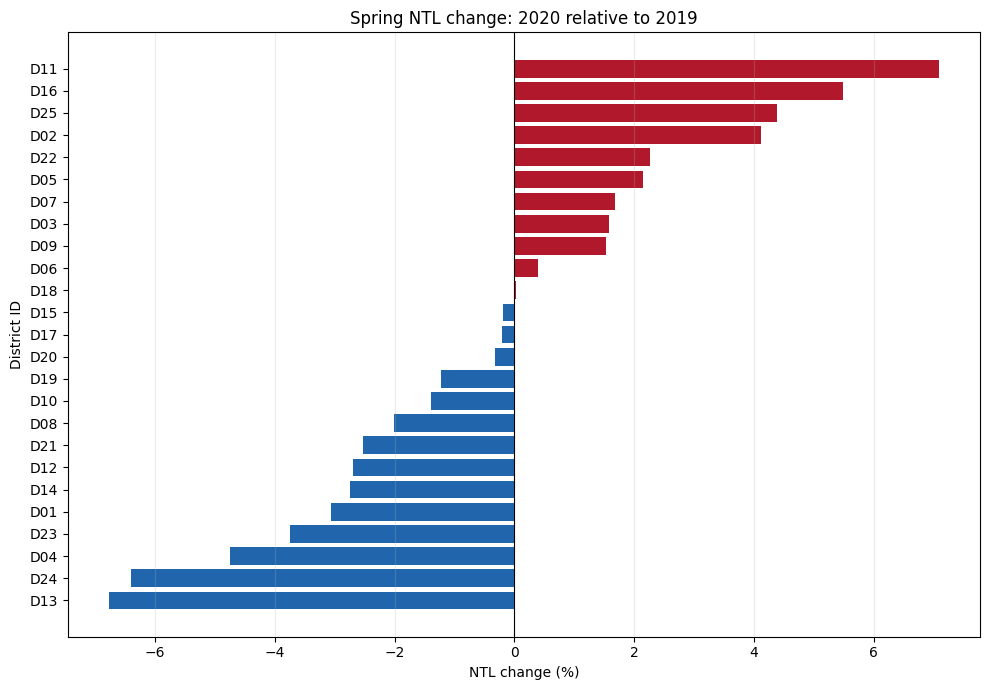

In [9]:
labels = gdf[['district_id','district_name']].copy()
labels['plot_id'] = [f'D{i:02d}' for i in range(1,26)]
labels.to_csv(OUT/'district_plot_labels.csv', index=False, encoding='utf-8-sig')
display(labels)
plot_df = comparison.merge(labels[['district_id','plot_id']], on='district_id')
valid = plot_df[plot_df.pair_status.eq('ok')].sort_values('ntl_change_pct')
if not valid.empty:
    fig, ax = plt.subplots(figsize=(10,7))
    ax.barh(valid.plot_id, valid.ntl_change_pct,
            color=np.where(valid.ntl_change_pct < 0, '#2166ac', '#b2182b'))
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set(xlabel='NTL change (%)', ylabel='District ID',
           title='Spring NTL change: 2020 relative to 2019')
    ax.grid(axis='x', alpha=.25)
    fig.tight_layout()
    fig.savefig(OUT/'ntl_change_bar.png', dpi=200)
    plt.show()
else:
    print('비교 가능한 구가 없습니다. 품질 표를 먼저 확인하세요.')


## M04 봄철 평균 영상·차이 지도
외부 배경지도를 제거해 API 키/403 오류를 피합니다. 두 해 6개월 모두 유효한 동일 위치에서만 영상 차이를 표시합니다. 연도별 평균 영상도 이 공통 위치에 맞춥니다.
지도는 픽셀의 시간평균이며 통계표는 구별 공간평균 후 시간평균이므로, 월별 관측 위치가 바뀌는 기본 모드에서는 지도와 통계표의 집계 대상이 다릅니다. 지도는 보조 자료입니다. 표시 제외는 불빛 0을 뜻하지 않습니다.

In [10]:
VIS = {'min':0, 'max':60, 'palette':['000004','51127c','b73779','fc8961','fcfdbf']}
DIFF_VIS = {'min':-10,'max':10,'palette':['2166ac','92c5de','f7f7f7','f4a582','b2182b']}
spring_images = {}
for year in YEARS:
    part = ready.filterDate(f'{year}-03-01', f'{year}-06-01').select('NTL')
    spring_images[year] = part.mean().updateMask(common).clip(roi)
images = [(spring_images[2019], VIS, '2019 spring NTL'),
          (spring_images[2020], VIS, '2020 spring NTL'),
          (spring_images[2020].subtract(spring_images[2019]), DIFF_VIS, '2020 minus 2019 NTL')]
maps = []
for index, (img, vis, title) in enumerate(images, 1):
    m = geemap.Map(center=[37.56,126.98], zoom=11)
    m.layers = ()
    m.addLayer(img, vis, title)
    m.addLayer(regions.style(color='00FFFF', fillColor='00000000', width=1), {}, 'District boundaries')
    m.add_colorbar(vis_params=vis, label='NTL (nW/cm²/sr)')
    print(title)
    display(m)
    maps.append(m)
print('차이 지도: 빨강=증가 / 파랑=감소. 단위는 %가 아닌 nW/cm²/sr입니다.')


2019 spring NTL


Map(center=[37.56, 126.98], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright…

2020 spring NTL


Map(center=[37.56, 126.98], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright…

2020 minus 2019 NTL


Map(center=[37.56, 126.98], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright…

차이 지도: 빨강=증가 / 파랑=감소. 단위는 %가 아닌 nW/cm²/sr입니다.


## M05 자치구별 변화율 지도
통계표와 동일한 결과를 자치구별 색으로 표시합니다. 회색 구는 품질 미달 또는 변화율 계산 불가입니다. -20~+20% 밖의 값도 실제 표에는 그대로 보존됩니다.

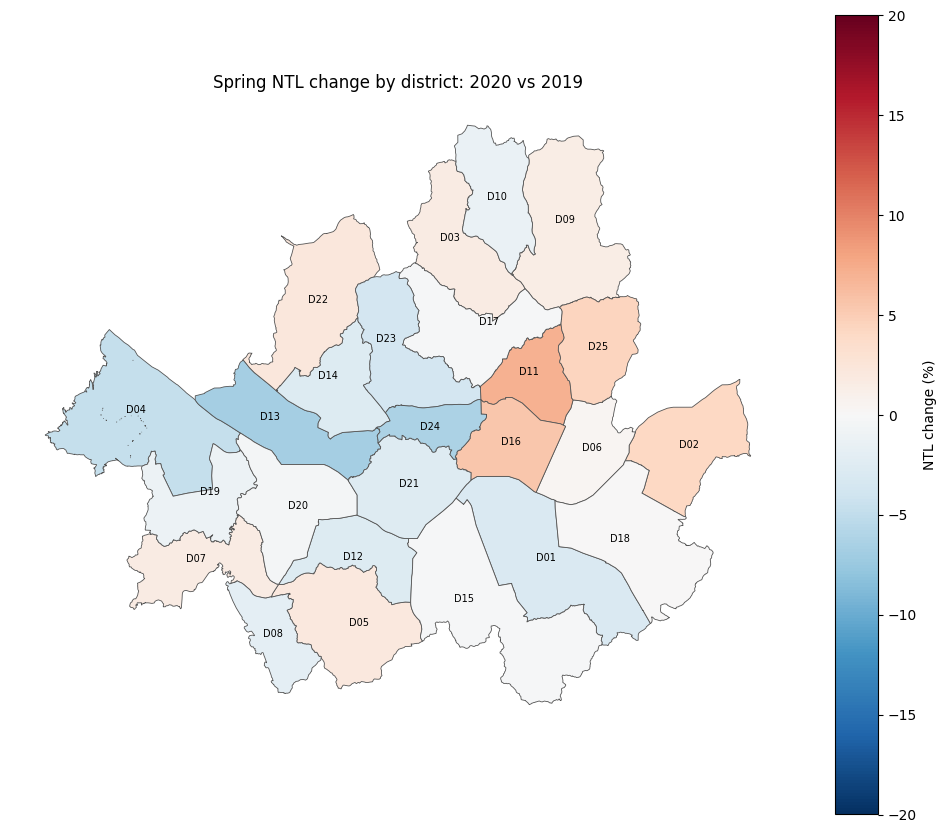

In [11]:
mapped = gdf.merge(comparison[['district_id','ntl_change_pct']], on='district_id', validate='one_to_one')
fig, ax = plt.subplots(figsize=(10,9))
mapped.plot(column='ntl_change_pct', cmap='RdBu_r', vmin=-20, vmax=20,
            edgecolor='#555555', linewidth=.6, legend=True,
            legend_kwds={'label':'NTL change (%)'},
            missing_kwds={'color':'lightgray'}, ax=ax)
annot = mapped.to_crs(5179)
points = annot.geometry.representative_point().to_crs(4326)
label_lookup = labels.set_index('district_id').plot_id
for idx, row in mapped.iterrows():
    point = points.loc[idx]
    ax.text(point.x, point.y, label_lookup[row.district_id], ha='center', fontsize=7)
ax.set_title('Spring NTL change by district: 2020 vs 2019')
ax.set_axis_off()
fig.tight_layout()
fig.savefig(OUT/'district_change_map.png', dpi=200)
plt.show()
